In [1]:
import sys
sys.path.append("../src")

from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance

from features import clean_data, build_pipeline

sns.set_theme(style="whitegrid")
FIG_DIR = Path("../reports/figures")

df = clean_data(pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"))
y = df["Churn"].map({"Yes": 1, "No": 0})
X = df.drop(columns=["Churn", "customerID"])

# Same split as before: same random_state, so the same test customers
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

best = joblib.load("../models/churn_pipeline.joblib")
print("Model loaded:", type(best).__name__)

Model loaded: Pipeline


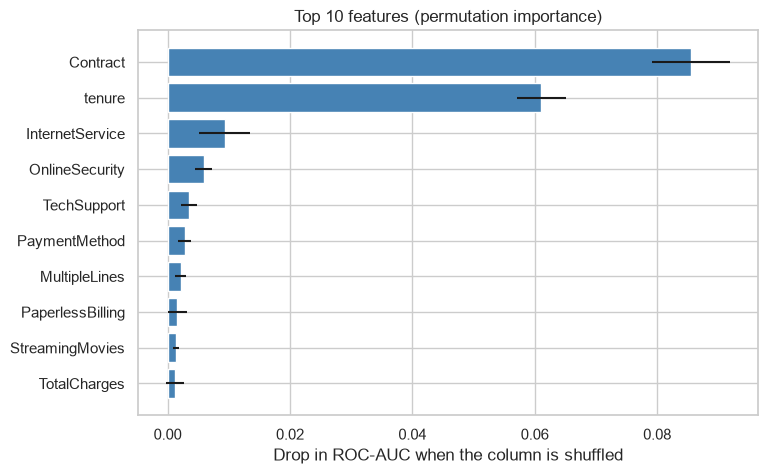

In [2]:
imp = permutation_importance(best, X_test, y_test, scoring="roc_auc",
                             n_repeats=10, random_state=42, n_jobs=-1)

imp_df = (pd.DataFrame({"feature": X_test.columns,
                        "importance": imp.importances_mean,
                        "std": imp.importances_std})
          .sort_values("importance", ascending=False))
imp_df.head(10).round(4)
top = imp_df.head(10).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top["feature"], top["importance"], xerr=top["std"], color="steelblue")
plt.xlabel("Drop in ROC-AUC when the column is shuffled")
plt.title("Top 10 features (permutation importance)")
plt.savefig(FIG_DIR / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [3]:
lr = build_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced"))
lr.fit(X_train, y_train)

names = lr.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr.named_steps["model"].coef_[0], index=names)

table = pd.DataFrame({"coef": coefs, "odds_ratio": np.exp(coefs)}).round(2)

print("=== Raise churn risk the most ===")
print(table.sort_values("coef", ascending=False).head(10))
print("\n=== Lower churn risk the most ===")
print(table.sort_values("coef").head(10))

=== Raise churn risk the most ===
                                  coef  odds_ratio
cat__InternetService_Fiber optic  0.71        2.03
cat__Contract_Month-to-month      0.70        2.02
cat__tenure_group_49-72           0.34        1.41
cat__OnlineSecurity_No            0.24        1.27
num__num_addons                   0.23        1.26
cat__StreamingMovies_Yes          0.21        1.24
cat__StreamingTV_Yes              0.20        1.22
cat__TechSupport_No               0.20        1.22
num__TotalCharges                 0.19        1.21
cat__MultipleLines_Yes            0.16        1.18

=== Lower churn risk the most ===
                                         coef  odds_ratio
num__tenure                             -1.04        0.35
cat__Contract_Two year                  -0.83        0.43
num__MonthlyCharges                     -0.70        0.50
cat__InternetService_DSL                -0.64        0.53
cat__tenure_group_13-24                 -0.37        0.69
cat__PaperlessBilling_

In [4]:
full = X.copy()
full["Churn"] = y

for col in ["Contract", "InternetService", "PaymentMethod", "TechSupport"]:
    print(full.groupby(col)["Churn"].agg(rate="mean", customers="count").round(3)
              .sort_values("rate", ascending=False), "\n")

                 rate  customers
Contract                        
Month-to-month  0.427       3875
One year        0.113       1473
Two year        0.028       1695 

                  rate  customers
InternetService                  
Fiber optic      0.419       3096
DSL              0.190       2421
No               0.074       1526 

                            rate  customers
PaymentMethod                              
Electronic check           0.453       2365
Mailed check               0.191       1612
Bank transfer (automatic)  0.167       1544
Credit card (automatic)    0.152       1522 

                      rate  customers
TechSupport                          
No                   0.416       3473
Yes                  0.152       2044
No internet service  0.074       1526 



In [5]:
full = X.copy()
full["Churn"] = y

for col in ["Contract", "InternetService", "PaymentMethod", "TechSupport"]:
    print(full.groupby(col)["Churn"].agg(rate="mean", customers="count").round(3)
              .sort_values("rate", ascending=False), "\n")

                 rate  customers
Contract                        
Month-to-month  0.427       3875
One year        0.113       1473
Two year        0.028       1695 

                  rate  customers
InternetService                  
Fiber optic      0.419       3096
DSL              0.190       2421
No               0.074       1526 

                            rate  customers
PaymentMethod                              
Electronic check           0.453       2365
Mailed check               0.191       1612
Bank transfer (automatic)  0.167       1544
Credit card (automatic)    0.152       1522 

                      rate  customers
TechSupport                          
No                   0.416       3473
Yes                  0.152       2044
No internet service  0.074       1526 



In [6]:
proba = best.predict_proba(X_test)[:, 1]

bands = pd.cut(proba, bins=[0, 0.3, 0.6, 1.0],
               labels=["Low", "Medium", "High"], include_lowest=True)

band_table = (pd.DataFrame({"band": bands, "churned": y_test.values})
              .groupby("band", observed=True)["churned"]
              .agg(customers="count", real_churn_rate="mean").round(3))
band_table

,customers,real_churn_rate
band,,
Low,620,0.047
Medium,319,0.238
High,470,0.572


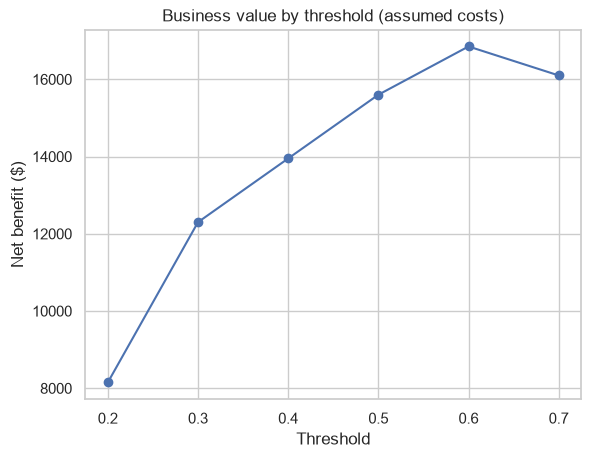

In [7]:
VALUE_SAVED = 500        # assumed value of keeping one customer ($)
OFFER_COST = 50          # assumed cost of one retention offer ($)
SUCCESS_RATE = 0.30      # assumed share of contacted churners who accept and stay

rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    flagged = proba >= t
    caught = (flagged & (y_test.values == 1)).sum()
    profit = caught * SUCCESS_RATE * VALUE_SAVED - flagged.sum() * OFFER_COST
    rows.append({"threshold": t, "flagged": int(flagged.sum()),
                 "churners_caught": int(caught), "net_benefit_$": round(profit)})
biz = pd.DataFrame(rows)
biz
plt.plot(biz["threshold"], biz["net_benefit_$"], marker="o")
plt.xlabel("Threshold"); plt.ylabel("Net benefit ($)")
plt.title("Business value by threshold (assumed costs)")
plt.savefig(FIG_DIR / "threshold_business_value.png", dpi=150, bbox_inches="tight")
plt.show()

threshold              0.6
flagged              470.0
churners_caught      269.0
net_benefit_$      16850.0
Name: 4, dtype: float64

## What drives churn? (interpretation)

**Main factors (permutation importance + logistic regression + raw rates agree):**
1. **Contract type**: month-to-month customers churn ~X% vs ~X% on two-year contracts.
2. **Tenure / customer age**: risk is highest in the first 12 months.
3. **Internet service**: fiber optic customers show a higher churn rate (~X%).
4. **Support services**: customers without tech support / online security churn more.
5. **Payment method**: electronic check users show higher churn than automatic payers.
6. **Monthly charges**: higher bills are associated with higher churn.

**Not important:** gender and other columns with near-zero importance.

**Caution (causation):** these are associations. For example, fiber customers may churn
because of price, service quality or competitors; the data cannot tell. To test a cause,
we would run an A/B test, such as offering a random group a contract discount.

**Caution (correlated features):** tenure, TotalCharges and tenure_group overlap, so their
importance is shared and individual values should not be over-interpreted.

**Business suggestions (hypotheses to test, not proven fixes):**
- Offer incentives to move month-to-month customers to longer contracts.
- Run a check-in programme in the first 12 months.
- Encourage automatic payment.
- Bundle tech support / online security for new fiber customers.

**Score meaning:** scores are risk scores (class weights), not exact probabilities.
Risk bands: Low X%, Medium X%, High X% real churn rate.